# 08 — 2026-10-25: the full run (as 06) with InternVL2.5-8B

Settings in `configs/2026-10-25_internvl_full.toml`, results in `outputs/2026-10-25_internvl_full/`; `prob_*` and `answer` use the original option letters, `option_order` and `answer_shown` what the model saw.

In [1]:
N_QUESTIONS = None  # None = all 598 questions
CONDITIONS = None  # None = all conditions in the config

In [2]:
import sys, json, random, time, tomllib
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import internvl as mdl

CFG_PATH = ROOT / "configs/2026-10-25_internvl_full.toml"
CFG = tomllib.loads(CFG_PATH.read_text())
CONDITIONS = CONDITIONS or CFG["conditions"]
assert set(CONDITIONS) <= set(CFG["conditions"]), CONDITIONS
EXP_DIR = ROOT / "outputs" / CFG["experiment"]
EXP_DIR.mkdir(parents=True, exist_ok=True)
OUT = EXP_DIR / "results.jsonl"

all_questions = pd.read_parquet(ROOT / "data-private/processed/emotion_questions.parquet")
questions = all_questions.head(N_QUESTIONS)
print(f"{len(questions)} questions, conditions {CONDITIONS} -> {OUT.relative_to(ROOT)}")

598 questions, conditions ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis'] -> outputs/2026-10-25_internvl_full/results.jsonl


## Mismatched clips

Each question gets the clip of an Emotions question from a different film with the closest clip length.

In [3]:
mismatch = {}
for q in all_questions.itertuples():
    other = all_questions[all_questions.movie_title != q.movie_title]
    gap = (other.focused_duration_s - q.focused_duration_s).abs()
    mismatch[q.question_id] = other.loc[gap.idxmin()]

pairs = pd.DataFrame({"question_id": list(mismatch),
                      "clip_s": all_questions.focused_duration_s.values,
                      "mis_question_id": [m.question_id for m in mismatch.values()],
                      "mis_movie_title": [m.movie_title for m in mismatch.values()],
                      "mis_clip_s": [m.focused_duration_s for m in mismatch.values()]})
pairs.to_csv(EXP_DIR / "mismatch_pairs.csv", index=False)
print("median |clip length difference| (s):", round((pairs.clip_s - pairs.mis_clip_s).abs().median(), 2))
pairs.head().round(1)

median |clip length difference| (s): 0.05


,question_id,clip_s,mis_question_id,mis_movie_title,mis_clip_s
0,FH-76,21.3,x40a1,MAN TO MAN,21.2
1,97rJU,47.5,ZNAaV,DUSSELDORF,47.6
2,cP4lM,294.0,hjEci,POMMEL,291.1
3,XESWo,55.0,iBIiz,COOL FOR FIVE SECONDS,55.1
4,6p7dK,21.4,kREcQ,THE REFEREE,21.4


## Option order

In [4]:
SHOWN = ["A", "B", "C", "D", "E"]


def option_order(question_id, with_e=True):
    order = ["A", "B", "C", "D", "E"]
    random.Random(f"{CFG['shuffle_seed']}-{question_id}").shuffle(order)
    return order if with_e else [x for x in order if x != "E"]


EVIDENCE = CFG["evidence_options"]


def evidence_order(question_id):
    order = list(EVIDENCE)
    random.Random(f"{CFG['shuffle_seed']}-{question_id}-evidence").shuffle(order)
    return order


def evidence_prompt(order):
    options = [f"{shown}. {EVIDENCE[name]}" for shown, name in zip(SHOWN, order)]
    return CFG["evidence_question"] + "\n" + "\n".join(options) + "\n\nAnswer with the option's letter only."


e_position = pd.Series([SHOWN[option_order(qid).index("E")] for qid in all_questions.question_id])
print('"Cannot tell" shown as:', e_position.value_counts().sort_index().to_dict())

"Cannot tell" shown as: {'A': 102, 'B': 106, 'C': 119, 'D': 138, 'E': 133}


## Load the model

In [5]:
processor, model = mdl.load(CFG["model_revision"])
print("device:", model.device)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/733 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie model.language_model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


device: cuda:0


## Show the exact prompts for the first question

In [6]:
first = questions.iloc[0]
order = option_order(first.question_id)
print("option order:", "".join(order))
for title, text in [("Q_noE", mdl.build_prompt(first, with_transcript=False, order=option_order(first.question_id, with_e=False))),
                    ("Q", mdl.build_prompt(first, with_transcript=False, option_e=CFG["option_e"], order=order)),
                    ("T_told", CFG["told_note"] + "\n\n" + mdl.build_prompt(first, option_e=CFG["option_e"], order=order)),
                    ("T, VT, VTmis", mdl.build_prompt(first, option_e=CFG["option_e"], order=order))]:
    print(f"===== {title}")
    print(mdl.make_inputs(processor, None, text)[1])
print("===== branch A: free-form explanation (T)")
print(mdl.make_inputs(processor, None, text, followup=("A", CFG["explain_prompt"]))[1])
print("===== branch B: evidence question (T)")
print(mdl.make_inputs(processor, None, text, followup=("A", evidence_prompt(evidence_order(first.question_id))))[1])

option order: CBEDA
===== Q_noE
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. The man expresses nervousness.
D. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== Q
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. Cannot tell from the given information.
D. The man expresses nervousness.
E. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== T_told
<|im_start|>user
A video of this scene exists, but it is not shown to you.

Transcript of the dialogue in the clip:
(no dialogue)

Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The ma

## Run

In [7]:
done = {(r["question_id"], r["condition"]) for r in map(json.loads, OUT.open())} if OUT.exists() else set()
print(f"{len(done)} results already in {OUT.name}")

for q in tqdm(questions.itertuples(), total=len(questions), unit="question"):
    for condition in CONDITIONS:
        if (q.question_id, condition) in done:
            continue
        t0 = time.time()

        option_e = None if condition == "Q_noE" else CFG["option_e"]
        order = option_order(q.question_id, with_e=condition != "Q_noE")
        shown = SHOWN[:len(order)]
        user_text = mdl.build_prompt(q._asdict(), with_transcript=condition in ["T", "T_told", "VT", "VTmis"],
                                    option_e=option_e, order=order)
        if condition == "T_told":
            user_text = CFG["told_note"] + "\n\n" + user_text

        clip, frames, fps = None, None, None
        if condition == "VT":
            clip = q
        if condition == "VTmis":
            clip = mismatch[q.question_id]
        if clip is not None:
            video = ROOT / "data-private/raw/all_videos" / f"{clip.movie_title}.mp4"
            frames, fps = mdl.sample_frames(video, clip.t_i, clip.t_j, int(clip.n_frames), CFG["max_pixels"])

        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps)
        r = mdl.score_options(model, processor, inputs, shown)
        top = r["prob"].index(max(r["prob"]))
        answer_shown, answer = shown[top], order[top]
        t1 = time.time()

        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, CFG["explain_prompt"]))
        e = mdl.generate_text(model, processor, inputs, CFG["explain_max_new_tokens"])
        t2 = time.time()

        ev_order = evidence_order(q.question_id)
        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, evidence_prompt(ev_order)))
        ev = mdl.score_options(model, processor, inputs, SHOWN[:len(ev_order)])

        row = {"order": q.order, "question_id": q.question_id, "condition": condition,
               **{f"prob_{L}": p for L, p in zip(order, r["prob"])},
               "mass_on_letters": r["mass_on_letters"], "n_input_tokens": r["n_input_tokens"], "answer": answer, "answer_shown": answer_shown, "option_order": "".join(order),
               "explanation": e["text"], "explanation_tokens": e["n_tokens"], "explanation_hit_limit": e["hit_limit"],
               **{f"evidence_prob_{name}": p for name, p in zip(ev_order, ev["prob"])},
               "evidence_answer": ev_order[ev["prob"].index(max(ev["prob"]))],
               "evidence_order": ",".join(ev_order), "evidence_mass_on_letters": ev["mass_on_letters"],
               "score_seconds": round(t1 - t0, 1), "explain_seconds": round(t2 - t1, 1), "evidence_seconds": round(time.time() - t2, 1),
               "video_question_id": None if clip is None else clip.question_id,
               "n_frames": 0 if frames is None else len(frames),
               "max_pixels": CFG["max_pixels"], "model_revision": CFG["model_revision"], "device": str(model.device)}
        with OUT.open("a") as f:
            f.write(json.dumps(row) + "\n")

60 results already in results.jsonl


  0%|          | 0/598 [00:00<?, ?question/s]

qwen-vl-utils using decord to read video.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (16908 > 8192). Running this sequence through the model will result in indexing errors
[h264 @ 0x555da63f2a40] mmco: unref short failure
[h264 @ 0x555da63f2a40] mmco: unref short failure
[h264 @ 0x555da63f2a40] mmco: unref short failure
[h264 @ 0x555da63f2a40] mmco: unref short failure
[h264 @ 0x555da63f2a40] mmco: unref short failure
[h264 @ 0x555da63ef000] mmco: unref short failure
[h264 @ 0x555da614fc40] mmco: unref short failure
[h264 @ 0x555da614fc40] mmco: unref short failure
[h264 @ 0x555da64032c0] mmco: unref short failure
[h264 @ 0x555da6b80d40] mmco: unref short failure
[h264 @ 0x555da6951f40] mmco: unref short failure
[h264 @ 0x555da6951f40] mmco: unref short failure
[h264 @ 0x555da6b80d40] mmco: unref short failure
[h264 @ 0x555da6b80d40] mmco: unref short failure
[h264 @ 0x555da6b64140] mmco: unref short failure
[h264 @ 

## Results so far

In [8]:
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

HIGH_CONFIDENCE = 0.8
FIGURES = EXP_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

keys = pd.read_parquet(ROOT / "data-private/processed/answer_keys.parquet")[["question_id", "correct_answer_key"]]
info = all_questions[["question_id", "movie_title", "question", "cue_visual_any"]]
df = pd.read_json(OUT, lines=True).drop_duplicates(["question_id", "condition"]).merge(keys, on="question_id").merge(info, on="question_id")

n_conditions = df.groupby("question_id").condition.transform("nunique")
df = df[n_conditions == df.condition.nunique()].copy()
conditions = [c for c in CFG["conditions"] if c in set(df.condition)]
print(df.question_id.nunique(), "questions with all of", conditions)

abcd = ["prob_A", "prob_B", "prob_C", "prob_D"]
df["abstain"] = df.answer == "E"
df["p_E"] = df.prob_E.fillna(0)
df["correct"] = df.answer == df.correct_answer_key
df["confidence"] = df[abcd].max(axis=1) / df[abcd].sum(axis=1)
df["confidently_wrong"] = ~df.correct & ~df.abstain & (df.confidence >= HIGH_CONFIDENCE)

598 questions with all of ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis']


In [9]:
summary = df.groupby("condition").agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    abstain=("abstain", "mean"),
    mean_p_E=("p_E", "mean"),
    confidence=("confidence", "mean"),
    confidently_wrong=("confidently_wrong", "mean"),
    mass_on_letters=("mass_on_letters", "mean"),
    score_seconds=("score_seconds", "mean"),
    explain_seconds=("explain_seconds", "mean"),
    evidence_seconds=("evidence_seconds", "mean"),
).reindex(conditions)
summary.insert(3, "selective_accuracy", df[~df.abstain].groupby("condition").correct.mean())
summary.round(3)

,n,accuracy,abstain,selective_accuracy,mean_p_E,confidence,confidently_wrong,mass_on_letters,score_seconds,explain_seconds,evidence_seconds
condition,,,,,,,,,,,
Q_noE,598,0.443,0.000,0.443,0.000,0.691,0.152,1.0,0.071,1.084,0.013
Q,598,0.189,0.587,0.457,0.503,0.680,0.092,1.0,0.013,1.013,0.013
T,598,0.324,0.420,0.559,0.410,0.758,0.105,1.0,0.016,1.149,0.016
T_told,598,0.291,0.538,0.630,0.495,0.757,0.077,1.0,0.016,1.146,0.016
VT,598,0.490,0.137,0.568,0.169,0.756,0.140,1.0,5.502,5.021,4.055
VTmis,598,0.421,0.157,0.500,0.197,0.720,0.139,1.0,5.418,5.076,3.983


By visual-cue tag:

In [10]:
df.pivot_table(index="condition", columns="cue_visual_any", values=["correct", "abstain", "p_E", "confidently_wrong"],
               aggfunc="mean").reindex(conditions).round(3)

abstain        confidently_wrong        correct           p_E  \
cue_visual_any   False  True              False  True    False  True   False   
condition                                                                      
Q_noE            0.000  0.000             0.217  0.140   0.337  0.462  0.000   
Q                0.457  0.611             0.141  0.083   0.207  0.186  0.418   
T                0.370  0.429             0.098  0.107   0.337  0.322  0.357   
T_told           0.511  0.543             0.076  0.077   0.293  0.291  0.435   
VT               0.098  0.144             0.185  0.132   0.489  0.490  0.135   
VTmis            0.120  0.164             0.152  0.136   0.402  0.425  0.160   

                       
cue_visual_any  True   
condition              
Q_noE           0.000  
Q               0.518  
T               0.419  
T_told          0.506  
VT              0.176  
VTmis           0.204

### Paired comparisons (Wilcoxon)

In [11]:
wide = df.pivot(index="question_id", columns="condition", values=["p_E", "confidence"])
rows = []
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    if a not in conditions or b not in conditions:
        continue
    for measure in ["p_E", "confidence"]:
        diff = wide[measure][b] - wide[measure][a]
        rows.append({"comparison": f"{b} - {a}", "measure": measure, "n": len(diff),
                     "mean_diff": diff.mean(), "median_diff": diff.median(),
                     "p": wilcoxon(diff).pvalue if (diff != 0).any() else None})
pd.DataFrame(rows).round(4)

,comparison,measure,n,mean_diff,median_diff,p
0,T - Q,p_E,598,-0.0930,-0.0758,0.0000
1,T - Q,confidence,598,0.0786,0.0455,0.0000
2,T_told - T,p_E,598,0.0854,0.0608,0.0000
3,T_told - T,confidence,598,-0.0015,-0.0001,0.4724
4,VT - T,p_E,598,-0.2402,-0.1622,0.0000
5,VT - T,confidence,598,-0.0019,-0.0030,0.4295
6,VTmis - VT,p_E,598,0.0279,0.0076,0.0000
7,VTmis - VT,confidence,598,-0.0358,-0.0208,0.0000
8,VTmis - T,p_E,598,-0.2123,-0.1468,0.0000
9,VTmis - T,confidence,598,-0.0378,-0.0267,0.0000


### Plot

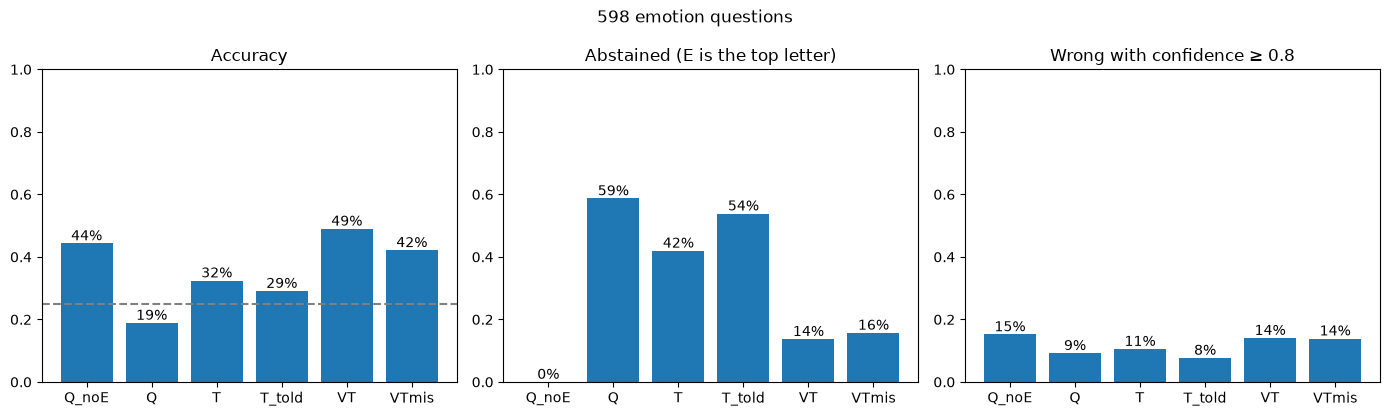

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, title in [(axes[0], "accuracy", "Accuracy"),
                       (axes[1], "abstain", "Abstained (E is the top letter)"),
                       (axes[2], "confidently_wrong", f"Wrong with confidence ≥ {HIGH_CONFIDENCE}")]:
    ax.bar(summary.index, summary[col], color="tab:blue")
    for i, value in enumerate(summary[col]):
        ax.text(i, value + 0.01, f"{value:.0%}", ha="center")
    ax.set(title=title, ylim=(0, 1))
axes[0].axhline(0.25, ls="--", c="gray")
fig.suptitle(f"{df.question_id.nunique()} emotion questions")
fig.tight_layout()
fig.savefig(FIGURES / "summary_by_condition.png", dpi=200)
plt.show()

### More plots

In [13]:
import numpy as np

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e2dc"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "font.size": 11, "legend.frameon": False})

def bootstrap_ci(values, n_resamples=2000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    means = [rng.choice(values, len(values)).mean() for _ in range(n_resamples)]
    return np.percentile(means, [2.5, 97.5])

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * (p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5 / (1 + z**2 / n)
    return centre - half, centre + half

df["forced_answer"] = df[abcd].idxmax(axis=1).str[-1]
df["forced_correct"] = df.forced_answer == df.correct_answer_key
df["no_dialogue"] = df.question_id.map(all_questions.set_index("question_id").focused_n_words) == 0
df["outcome"] = np.where(df.abstain, "abstain", np.where(df.correct, "right", "wrong"))
with_e = [c for c in conditions if c != "Q_noE"]

#### 1. Abstention follows the evidence

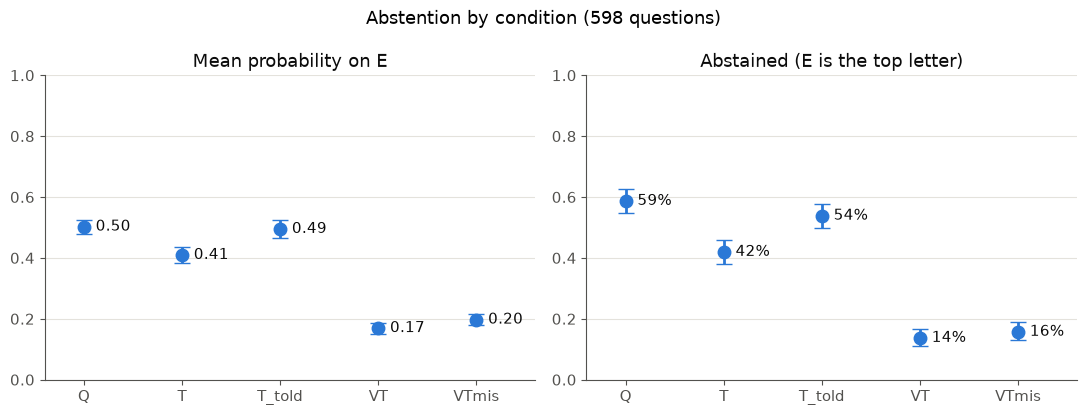

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, title in zip(axes, ["Mean probability on E", "Abstained (E is the top letter)"]):
    for i, condition in enumerate(with_e):
        g = df[df.condition == condition]
        if title.startswith("Mean"):
            value, (lo, hi) = g.p_E.mean(), bootstrap_ci(g.p_E)
        else:
            value, (lo, hi) = g.abstain.mean(), wilson(g.abstain.sum(), len(g))
        ax.errorbar(i, value, yerr=[[value - lo], [hi - value]], fmt="o", ms=9, color=BLUE, capsize=6, lw=2)
        ax.text(i + 0.12, value, f"{value:.2f}" if title.startswith("Mean") else f"{value:.0%}", va="center", color=INK)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.4, len(with_e) - 0.4), title=title)
fig.suptitle(f"Abstention by condition ({df.question_id.nunique()} questions)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_by_condition.png", dpi=200)
plt.show()

#### 2. The video changes *whether* the model answers, not *what* it answers

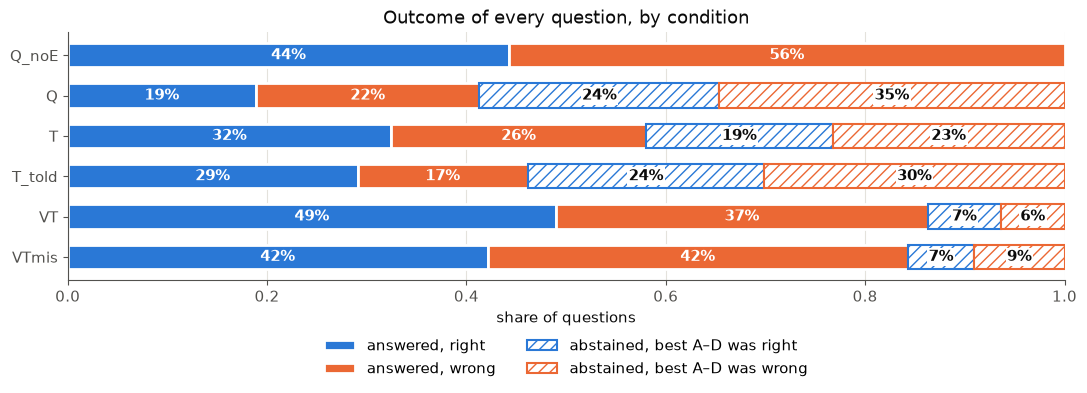

accuracy among answered: {'Q_noE': 0.443, 'Q': 0.457, 'T': 0.559, 'T_told': 0.63, 'VT': 0.568, 'VTmis': 0.5}
forced A-D accuracy:    {'Q_noE': 0.445, 'Q': 0.43, 'T': 0.512, 'T_told': 0.527, 'VT': 0.564, 'VTmis': 0.49}


In [15]:
parts = [("answered, right", ~df.abstain & df.correct, BLUE, None),
         ("answered, wrong", ~df.abstain & ~df.correct, ORANGE, None),
         ("abstained, best A–D was right", df.abstain & df.forced_correct, BLUE, "///"),
         ("abstained, best A–D was wrong", df.abstain & ~df.forced_correct, ORANGE, "///")]

fig, ax = plt.subplots(figsize=(11, 4.2))
rows = np.arange(len(conditions))
left = np.zeros(len(conditions))
for label, mask, color, hatch in parts:
    share = mask.groupby(df.condition).mean().reindex(conditions).values
    hatched = hatch is not None
    keep = share > 0
    ax.barh(rows[keep], share[keep], left=left[keep], color="white" if hatched else color, edgecolor=color if hatched else "white",
            hatch=hatch, linewidth=1.5 if hatched else 2, label=label, height=0.6)
    for y, (x, w) in enumerate(zip(left, share)):
        if w >= 0.06:
            ax.text(x + w / 2, y, f"{w:.0%}", ha="center", va="center", color=INK if hatched else "white",
                    fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1) if hatched else None)
    left += share
ax.set_yticks(rows, conditions)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="share of questions", title="Outcome of every question, by condition")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig(FIGURES / "outcomes_by_condition.png", dpi=200)
plt.show()

print("accuracy among answered:", df[~df.abstain].groupby("condition").correct.mean().reindex(conditions).round(3).to_dict())
print("forced A-D accuracy:   ", df.groupby("condition").forced_correct.mean().reindex(conditions).round(3).to_dict())

#### 3. Question by question: P(E) with and without the (right) video

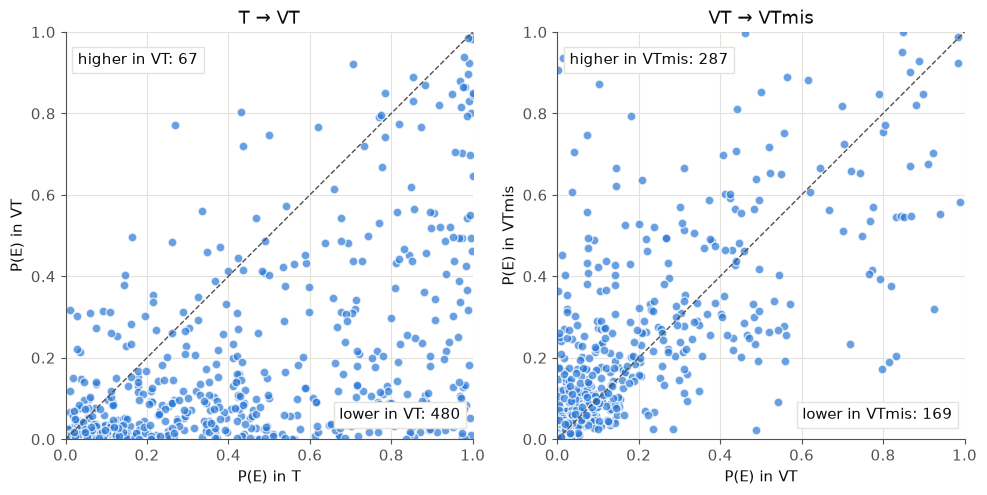

In [16]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (a, b) in zip(axes, [("T", "VT"), ("VT", "VTmis")]):
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
    ax.scatter(pE[a], pE[b], s=40, color=BLUE, alpha=0.7, edgecolor="white", linewidth=1)
    up, down = (pE[b] > pE[a] + 0.01).sum(), (pE[b] < pE[a] - 0.01).sum()
    ax.text(0.03, 0.95, f"higher in {b}: {up}", transform=ax.transAxes, va="top", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.text(0.97, 0.05, f"lower in {b}: {down}", transform=ax.transAxes, ha="right", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel=f"P(E) in {a}", ylabel=f"P(E) in {b}", title=f"{a} → {b}")
    ax.grid(axis="both", color=GRID)
fig.tight_layout()
fig.savefig(FIGURES / "p_E_per_question.png", dpi=200)
plt.show()

#### 4. Where the answers move

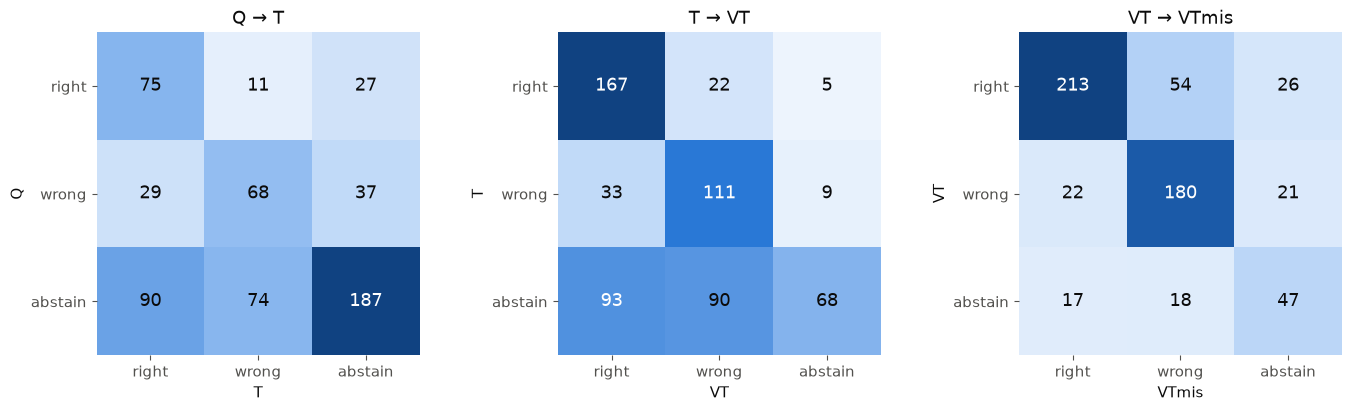

In [17]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#f5f9fe", "#9ec5f4", "#2a78d6", "#104281"])
outcome = df.pivot(index="question_id", columns="condition", values="outcome")
labels = ["right", "wrong", "abstain"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (a, b) in zip(axes, [("Q", "T"), ("T", "VT"), ("VT", "VTmis")]):
    table = pd.crosstab(outcome[a], outcome[b]).reindex(index=labels, columns=labels, fill_value=0)
    ax.imshow(table.values, cmap=blues, vmin=0, vmax=table.values.max())
    for i in range(3):
        for j in range(3):
            n = table.values[i, j]
            ax.text(j, i, n, ha="center", va="center", fontsize=13,
                    color="white" if n > table.values.max() * 0.55 else INK)
    ax.set(xticks=range(3), xticklabels=labels, yticks=range(3), yticklabels=labels,
           xlabel=b, ylabel=a, title=f"{a} → {b}")
    ax.grid(False)
    ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "outcome_transitions.png", dpi=200)
plt.show()

#### 5. Subgroups: visual-cue tag and clips without dialogue

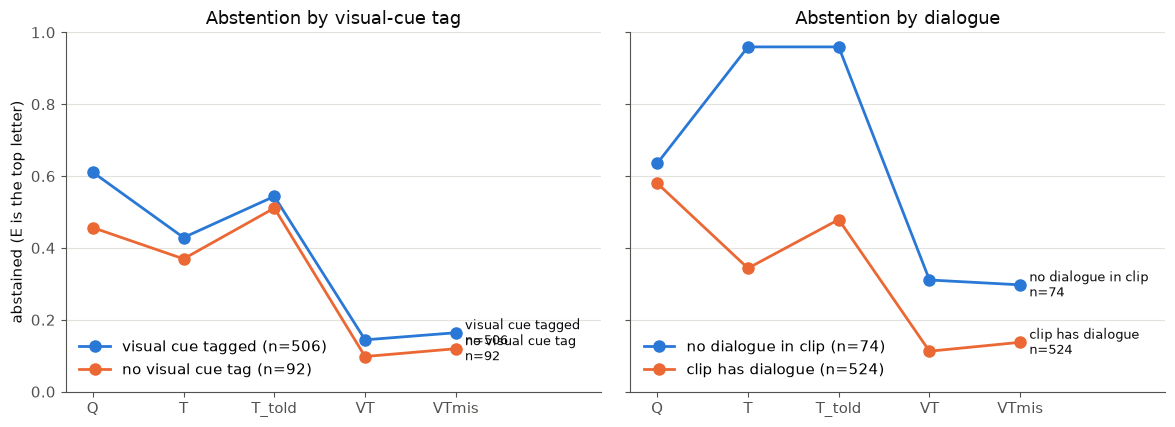

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (column, names) in zip(axes, [("cue_visual_any", {True: "visual cue tagged", False: "no visual cue tag"}),
                                      ("no_dialogue", {False: "clip has dialogue", True: "no dialogue in clip"})]):
    for value, color in [(True, BLUE), (False, ORANGE)]:
        g = df[(df[column] == value) & df.condition.isin(with_e)]
        rate = g.groupby("condition").abstain.mean().reindex(with_e)
        n = g.question_id.nunique()
        ax.plot(range(len(with_e)), rate.values, "o-", color=color, lw=2, ms=8, label=f"{names[value]} (n={n})")
        ax.text(len(with_e) - 1 + 0.1, rate.values[-1], f"{names[value]}\nn={n}", va="center", color=INK, fontsize=9)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.3, len(with_e) + 0.6),
           title=f"Abstention by {'visual-cue tag' if column == 'cue_visual_any' else 'dialogue'}")
    ax.legend(loc="lower left")
axes[0].set_ylabel("abstained (E is the top letter)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_subgroups.png", dpi=200)
plt.show()

## Explanations

In [19]:
explanations = df[["order", "question_id", "movie_title", "question", "condition", "option_order", "answer_shown", "answer",
                   "confidence", "p_E", "explanation", "evidence_answer", "explanation_hit_limit"]].sort_values(["order", "condition"])
explanations.to_csv(EXP_DIR / "explanations.csv", index=False)
print("explanations that hit the token limit:", explanations.explanation_hit_limit.sum())
pd.set_option("display.max_colwidth", None)
explanations.head(15)

explanations that hit the token limit: 8


,order,question_id,movie_title,question,condition,option_order,answer_shown,answer,confidence,p_E,explanation,evidence_answer,explanation_hit_limit
1,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,Q,CBEDA,C,E,0.828878,0.692603,The answer is based on the information that the man's feelings about knocking on the door are not explicitly described in the provided text.,nothing,False
0,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,Q_noE,CBDA,B,B,0.663213,0.000000,I based my answer on the information that the man expresses fear that there might not be anyone inside.,nothing,False
2,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,T,CBEDA,C,E,0.762073,0.985632,"The answer is based on the fact that there is no dialogue provided in the clip, making it impossible to determine the man's feelings about knocking on the door.",nothing,False
3,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,T_told,CBEDA,C,E,0.714590,0.990659,"The answer is based on the information that the transcript indicates there is ""no dialogue,"" which means there is no expression of feelings or thoughts from the man about knocking on the door.",nothing,False
4,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,VT,CBEDA,C,E,0.561698,0.543194,The video does not provide any information about the man's feelings regarding knocking on the door.,nothing,False
5,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,VTmis,CBEDA,B,B,0.959758,0.091865,"The man says, 'I'm afraid there's no one in there,' which indicates his fear that there might not be anyone inside.",video,False
7,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,Q,CDAEB,C,A,0.813855,0.153687,The information that the older woman's violent reaction causes the young woman to step back to avoid being hurt again.,nothing,False
6,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,Q_noE,CDAB,C,A,0.846709,0.000000,"The answer is based on the information that the young woman feels scared and steps back to avoid being hurt again, as indicated by her reaction to the older woman's violent behavior.",nothing,False
8,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,T,CDAEB,C,A,0.959253,0.057780,The young woman's reaction of stepping back and trying to avoid further contact indicates that she feels scared and is attempting to avoid being hurt again.,transcript,False
9,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,T_told,CDAEB,C,A,0.956055,0.114565,"The dialogue includes the young woman's plea for help and her request to be left alone, indicating she feels scared and steps back to avoid further harm.",transcript,False


### Visual words in the explanations (keyword screen)

In [20]:
VISUAL_WORDS = ["face", "facial", "expression", "smile", "smiling", "frown", "eyes", "gaze", "tears", "crying",
                "body language", "posture", "gesture", "video", "visible"]
pattern = r"\b(?:" + "|".join(VISUAL_WORDS) + r")\b"
explanations["mentions_visual"] = explanations.explanation.str.contains(pattern, case=False)
display(explanations.groupby("condition").mentions_visual.mean().reindex(conditions).round(3))
explanations[(explanations.condition == "VTmis") & explanations.mentions_visual & (explanations.answer != "E")].head(10)

condition
Q_noE     0.164
Q         0.094
T         0.077
T_told    0.099
VT        0.410
VTmis     0.321
Name: mentions_visual, dtype: float64

,order,question_id,movie_title,question,condition,option_order,answer_shown,answer,confidence,p_E,explanation,evidence_answer,explanation_hit_limit,mentions_visual
41,6,IESLM,MARYAM JOON,Why does the young woman touch the fruit to her face?,VTmis,ACBED,E,D,0.965606,0.262114,"The young woman touches the fruit to her face, and the other woman says, 'You want to be beautiful.' This suggests that the young woman desires to feel beautiful.",video,False,True
47,7,aWgG2,FATHER FIGURE,How does the woman feel when she looks at her son's new drawing?,VTmis,CEBDA,D,D,0.858864,0.129866,"The woman is smiling and looking at the drawing, indicating she is joyful and approving of it.",video,False,True
77,12,K45sv,REBEL,What does the little boy feel as he watches this situation?,VTmis,BDACE,D,C,0.763319,0.117112,The information about the little boy's feelings is directly stated in the video.,nothing,False,True
107,17,575hd,LITTLE GREY BUBBLES,"What is the man feeling after the protagonist says that she was ""one of his best friends""",VTmis,EBDAC,B,B,0.664433,0.103510,The man's facial expression changes from a smile to a look of shock and disappointment.,nothing,False,True
119,19,nDSVR,A SECRET JOURNEY,How is the protagonist feeling in this moment?,VTmis,AEDBC,D,B,0.922366,0.016613,"The protagonist says, 'It's just between the vomiting and the shitting blood and the crying, it's too much,' which indicates she is not satisfied and is feeling anxious about her situation.",transcript,False,True
125,20,q9D7b,MARTHA THE MONSTER,"What is ironic about the song lyrics being ""Happy, happy, happy""?",VTmis,ADBEC,E,C,0.962370,0.008257,"The man is crying, which suggests he is sad, not happy.",nothing,False,True
137,22,UoFUT,SOMETHING LIKE LONELINESS,What is the woman's emotional progression during the conversation?,VTmis,DECBA,D,B,0.648020,0.080629,The woman's facial expressions and body language change from neutral to embarrassed and then to nervous during the conversation.,both,False,True
203,33,JQ7mA,A GIRL AND HER GUN,How does the girl feel after tasting the ice cream?,VTmis,BCDEA,E,A,0.349544,0.174922,"The girl's expression and the fact that she says, ""Dad, you haven't cleaned the apartment in a long time,"" suggests that she is sad and disappointed.",nothing,False,True
239,39,jp69y,PEOPLE IN CARS,What is the emotional progression of the man on the left as the man on the right describes what happened?,VTmis,BDACE,C,A,0.990744,0.267119,The man on the left's facial expressions change from confusion to realization as the man on the right describes what happened.,both,False,True
287,47,zyN-U,AZIZ,What two emotions does the man in the back seat feel in this scene?,VTmis,BACDE,D,D,0.948341,0.365161,The man's facial expression and the context of the statement suggest he is nervous and fearful.,nothing,False,True


#### 6. What the explanations talk about (keyword screens)

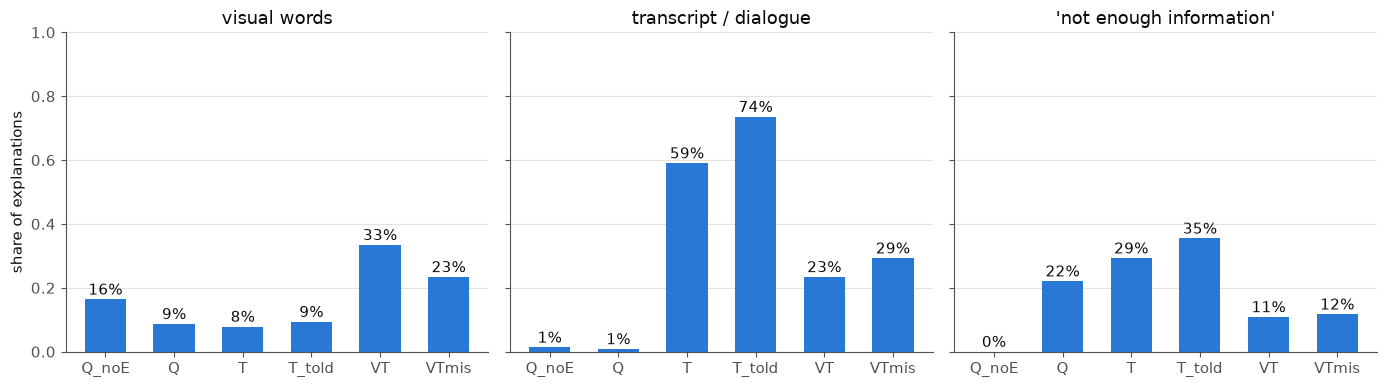

In [21]:
screens = {
    "visual words": r"\b(?:face|facial|expression|smil\w*|frown\w*|eyes|gaze|tears|cry\w*|body language|posture|gesture\w*)\b",
    "transcript / dialogue": r"\b(?:transcript|dialogue|says|said)\b",
    "'not enough information'": r"does not provide|not enough|cannot be determined|impossible to determine|no (?:information|dialogue|context)",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (title, pattern) in zip(axes, screens.items()):
    share = explanations.explanation.str.contains(pattern, case=False).groupby(explanations.condition).mean().reindex(conditions)
    ax.bar(conditions, share.values, color=BLUE, width=0.6)
    for i, v in enumerate(share.values):
        ax.text(i, v + 0.015, f"{v:.0%}", ha="center", color=INK)
    ax.set(title=title, ylim=(0, 1))
axes[0].set_ylabel("share of explanations")
fig.tight_layout()
fig.savefig(FIGURES / "explanation_screens.png", dpi=200)
plt.show()

## Told that a video exists (T_told vs T)

Abstention in T and T_told, split by whether the video changed the answer (VT vs T).

In [22]:
if {"T", "T_told", "VT"} <= set(conditions):
    answers = df.pivot(index="question_id", columns="condition", values="answer")
    video_mattered = (answers["VT"] != answers["T"]).rename("video_mattered")
    told = df[df.condition.isin(["T", "T_told"])].merge(video_mattered, left_on="question_id", right_index=True)
    display(told.pivot_table(index="video_mattered", columns="condition", values=["abstain", "p_E"], aggfunc="mean").round(3))
    print("questions per group:", video_mattered.value_counts().to_dict())

abstain           p_E       
condition            T T_told      T T_told
video_mattered                             
False            0.205  0.349  0.300  0.374
True             0.688  0.774  0.546  0.646

questions per group: {False: 332, True: 266}


## Evidence question (branch B)

In [23]:
evidence_names = list(EVIDENCE)
display(pd.crosstab(df.condition, df.evidence_answer, normalize="index")
        .reindex(index=conditions, columns=evidence_names, fill_value=0).round(3))
display(pd.crosstab([df.condition, df.abstain], df.evidence_answer, normalize="index")
        .reindex(columns=evidence_names, fill_value=0).round(3))
claims_video = df.evidence_answer.isin(["video", "both"])
print("claimed a video:", claims_video.groupby(df.condition).mean().reindex(conditions).round(3).to_dict())
print("mean evidence_mass_on_letters:", round(df.evidence_mass_on_letters.mean(), 3))

evidence_answer,nothing,transcript,video,both
condition,,,,
Q_noE,0.749,0.114,0.074,0.064
Q,0.941,0.045,0.003,0.010
T,0.221,0.773,0.002,0.005
T_told,0.247,0.753,0.000,0.000
VT,0.314,0.059,0.154,0.473
VTmis,0.440,0.080,0.105,0.375


evidence_answer    nothing  transcript  video   both
condition abstain                                   
Q         False      0.866       0.101  0.008  0.024
          True       0.994       0.006  0.000  0.000
Q_noE     False      0.749       0.114  0.074  0.064
T         False      0.049       0.939  0.003  0.009
          True       0.458       0.542  0.000  0.000
T_told    False      0.043       0.957  0.000  0.000
          True       0.422       0.578  0.000  0.000
VT        False      0.227       0.066  0.172  0.535
          True       0.866       0.012  0.037  0.085
VTmis     False      0.345       0.095  0.123  0.437
          True       0.947       0.000  0.011  0.043

claimed a video: {'Q_noE': 0.137, 'Q': 0.013, 'T': 0.007, 'T_told': 0.0, 'VT': 0.627, 'VTmis': 0.48}
mean evidence_mass_on_letters: 1.0


## Option position

In [24]:
e_conditions = [c for c in conditions if c != "Q_noE"]
df["e_shown_as"] = df.option_order.str.find("E").map(dict(enumerate(SHOWN)))
display(df[df.condition.isin(e_conditions)]
        .pivot_table(index="condition", columns="e_shown_as", values="abstain", aggfunc="mean")
        .reindex(e_conditions).round(3))
display(pd.crosstab(df.condition, df.answer_shown, normalize="index").reindex(conditions).round(3))

e_shown_as,A,B,C,D,E
condition,,,,,
Q,0.353,0.594,0.664,0.652,0.624
T,0.343,0.481,0.496,0.471,0.308
T_told,0.392,0.585,0.664,0.645,0.391
VT,0.078,0.189,0.168,0.181,0.068
VTmis,0.088,0.198,0.227,0.203,0.068


answer_shown,A,B,C,D,E
condition,,,,,
Q_noE,0.241,0.293,0.254,0.212,0.000
Q,0.134,0.222,0.249,0.206,0.189
T,0.167,0.209,0.264,0.199,0.161
T_told,0.151,0.204,0.256,0.234,0.156
VT,0.186,0.219,0.241,0.192,0.162
VTmis,0.157,0.249,0.247,0.204,0.142


## Run time

In [25]:
seconds = df.score_seconds + df.explain_seconds + df.evidence_seconds
display(seconds.groupby(df.condition).mean().reindex(conditions).round(1).rename("seconds per question"))
print(f"{seconds.sum() / 3600:.1f} GPU-hours for {df.question_id.nunique()} questions (model loading not included)")

condition
Q_noE      1.2
Q          1.0
T          1.2
T_told     1.2
VT        14.6
VTmis     14.5
Name: seconds per question, dtype: float64

5.6 GPU-hours for 598 questions (model loading not included)


## Additional tests (added 2026-10-19)

In [26]:
from scipy.stats import binomtest, chi2_contingency, chisquare, mannwhitneyu

abstained = df.pivot(index="question_id", columns="condition", values="abstain")
for condition in e_conditions:
    lo, hi = wilson(abstained[condition].sum(), len(abstained))
    print(f"{condition:7} abstained {abstained[condition].mean():.1%}  95% CI [{lo:.1%}, {hi:.1%}]")
print()
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    start = int((~abstained[a] & abstained[b]).sum())
    stop = int((abstained[a] & ~abstained[b]).sum())
    print(f"{a} -> {b}: {start} start abstaining, {stop} stop; exact McNemar p = {binomtest(start, start + stop).pvalue:.2g}")

Q       abstained 58.7%  95% CI [54.7%, 62.6%]
T       abstained 42.0%  95% CI [38.1%, 46.0%]
T_told  abstained 53.8%  95% CI [49.8%, 57.8%]
VT      abstained 13.7%  95% CI [11.2%, 16.7%]
VTmis   abstained 15.7%  95% CI [13.0%, 18.9%]

Q -> T: 64 start abstaining, 164 stop; exact McNemar p = 2.7e-11
T -> T_told: 72 start abstaining, 1 stop; exact McNemar p = 1.6e-20
T -> VT: 14 start abstaining, 183 stop; exact McNemar p = 1e-38
VT -> VTmis: 47 start abstaining, 35 stop; exact McNemar p = 0.22
T -> VTmis: 25 start abstaining, 182 stop; exact McNemar p = 1.3e-30


In [27]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
answers = df.pivot(index="question_id", columns="condition", values="answer")
video_mattered = answers["VT"] != answers["T"]
rise = pE["T_told"] - pE["T"]
print(f"P(E) rise T -> T_told: video mattered {rise[video_mattered].mean():+.3f} (n = {video_mattered.sum()}), "
      f"did not {rise[~video_mattered].mean():+.3f} (n = {(~video_mattered).sum()}); "
      f"Mann-Whitney p = {mannwhitneyu(rise[video_mattered], rise[~video_mattered]).pvalue:.2g}")

P(E) rise T -> T_told: video mattered +0.100 (n = 266), did not +0.073 (n = 332); Mann-Whitney p = 3.9e-06


In [28]:
for condition in e_conditions:
    g = df[df.condition == condition]
    p = chi2_contingency(pd.crosstab(g.e_shown_as, g.abstain))[1]
    print(f"abstention vs letter of 'Cannot tell', {condition}: chi-square p = {p:.2g}")
letters = df[df.condition == "Q_noE"].answer_shown.value_counts().reindex(["A", "B", "C", "D"])
print(f"Q_noE answers by shown letter: {letters.to_dict()}; chi-square vs equal p = {chisquare(letters).pvalue:.2g}")

abstention vs letter of 'Cannot tell', Q: chi-square p = 7.3e-06
abstention vs letter of 'Cannot tell', T: chi-square p = 0.0043
abstention vs letter of 'Cannot tell', T_told: chi-square p = 4.3e-07
abstention vs letter of 'Cannot tell', VT: chi-square p = 0.0073
abstention vs letter of 'Cannot tell', VTmis: chi-square p = 0.0006
Q_noE answers by shown letter: {'A': 144, 'B': 175, 'C': 152, 'D': 127}; chi-square vs equal p = 0.046


In [29]:
told = df[df.condition == "T_told"]
mentions_video = told.explanation.str.contains(r"\bvideo", case=False)
print(f"T_told explanations mentioning the video: {mentions_video.mean():.1%} "
      f"(abstentions {mentions_video[told.abstain].mean():.1%}, answers {mentions_video[~told.abstain].mean():.1%})")

T_told explanations mentioning the video: 2.7% (abstentions 4.0%, answers 1.1%)
